In [5]:
import random, time
import matplotlib.pyplot as plt
import threading
import _thread
import numpy as np
import urllib.request
import math
import heapq
from collections import deque, defaultdict, Counter
import csv
import networkx as nx

In [8]:
## Two protein sequences x and y of lengths n and m over the 20-letter amino-acid alphabet, 
## and an integer k. Decide whether x and y share a substring of length exactly k, and if so return one.

## 1.1. Implement the naive algorithm: for every position of x, compare the window of length k
## against every position of y. State and prove its worst-case bound in n, m and k.
def substring_shared(x, y, n, m, k):
    substring_length = 0
    for i in range(0, n - k + 1):
        for j in range(0, m - k + 1):
            substring_length = 0

            for window in range(k):
                if x[i + window] == y[j + window]:
                    substring_length += 1
                else:
                    break
            if substring_length == k:
                return 1

    return 0


In [9]:
## 1.2. Implement a hashing-based algorithm: store all k-mers of x in a set, then scan y. State
## and prove its expected bound. State what its worst-case bound is and when it occurs.

def find_kmer_hashing(x, y, n, m, k):

    if k == 0:
        return "Invalid k value, insert a k of at least two"
    if k > n or k > m:
        return None

    BASE = 131
    MOD = 10**9 + 7

    def val(c):
        return ord(c)

    def first_hash(s, start):
        h = 0
        for t in range(k):
            h = (h * BASE + val(s[start + t])) % MOD
        return h

    power = pow(BASE, k - 1, MOD)

    # Store hashes of all k-mers of x
    x_hashes = {}

    h = first_hash(x, 0)
    x_hashes.setdefault(h, []).append(0)

    for i in range(1, n - k + 1):
        h = (h - val(x[i - 1]) * power) % MOD
        h = (h * BASE + val(x[i + k - 1])) % MOD
        x_hashes.setdefault(h, []).append(i)

    # Scan y
    h = first_hash(y, 0)

    for j in range(m - k + 1):
        if j > 0:
            h = ((h - val(y[j - 1]) * power) * BASE + val(y[j + k - 1])) % MOD
        if h in x_hashes:
            for i in x_hashes[h]:
                if x[i:i + k] == y[j:j + k]:
                    return y[j:j + k]

    return None    


n=      10  k=  3  naive=2.8399983420968056e-05  hash=6.510003004223108e-05
n=      10  k= 10  naive=1.0699965059757233e-05  hash=3.869994543492794e-05
n=     100  k=  3  naive=0.0018698000349104404  hash=0.00013870000839233398
n=     100  k= 10  naive=0.0018293000757694244  hash=0.00016659998800605536
n=     100  k= 50  naive=0.00045489997137337923  hash=0.00018630002159625292
n=    1000  k=  3  naive=0.0013685999438166618  hash=0.000775099964812398
n=    1000  k= 10  naive=0.24923980003222823  hash=0.0014027999714016914
n=    1000  k= 50  naive=0.17894380004145205  hash=0.0010366999777033925
n=   10000  k=  3  naive=0.00024800002574920654  hash=0.007521399995312095
n=   10000  k= 10  naive=None  hash=0.009953200002200902
n=   10000  k= 50  naive=None  hash=0.010128600057214499
n=  100000  k=  3  naive=1.5099998563528061e-05  hash=0.06786879990249872
n=  100000  k= 10  naive=None  hash=0.16298889997415245
n=  100000  k= 50  naive=None  hash=0.15952019998803735
n= 1000000  k=  3  naive

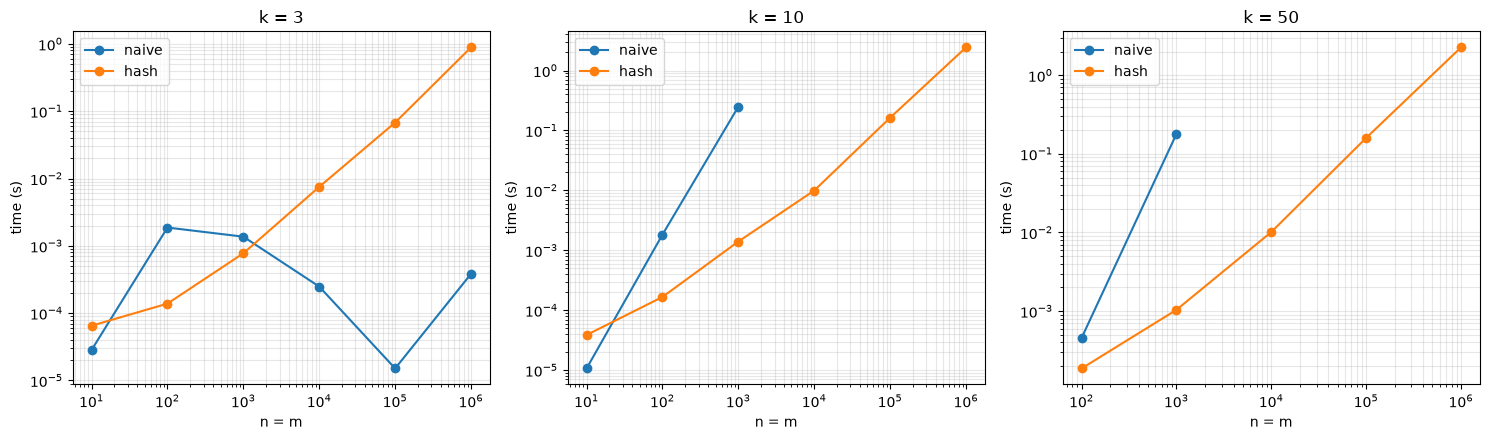

In [10]:
## 1.3. Benchmark both on random sequences with n = m ∈ {103, 104, 105, 106} 
## and k ∈ {3, 10, 50}.Plot running time against n for each k, and report 
## the crossover point at which the hash-ing algorithm becomes faster. 
## Explain why the naive algorithm wins below it, in terms of the constants that the asymptotic bound hides.


def time_call(f, args, limit=10):
    """Return elapsed seconds, or None if it exceeds `limit`."""
    def kill():
        _thread.interrupt_main()      # raises KeyboardInterrupt in main thread

    timer = threading.Timer(limit, kill)
    timer.start()
    try:
        start = time.perf_counter()
        f(*args)
        return time.perf_counter() - start
    except KeyboardInterrupt:
        return None
    finally:
        timer.cancel()

# ---------- benchmark ----------
sizes = [10, 100, 1_000, 10_000, 100_000, 1_000_000]
ks    = [3, 10, 50]
alphabet = "ACDEFGHIKLMNPQRSTVWY"
rng = random.Random(0)

# results[k] = {'naive': [(n, t), ...], 'hash': [(n, t), ...]}
results = {k: {'naive': [], 'hash': []} for k in ks}

for n in sizes:
    x = ''.join(rng.choice(alphabet) for _ in range(n))
    y = ''.join(rng.choice(alphabet) for _ in range(n))

    for k in ks:
        if k > n:
            continue

        t_naive = time_call(substring_shared, (x, y, n, n, k))
        t_hash  = time_call(find_kmer_hashing, (x, y, n, n, k))

        results[k]['naive'].append((n, t_naive))
        results[k]['hash'].append((n, t_hash))

        print(f"n={n:>8}  k={k:>3}  "
              f"naive={t_naive}  hash={t_hash}")

# ---------- crossover report ----------
print("\nCrossover points:")
for k in ks:
    prev_winner = None
    for (n, tn), (_, th) in zip(results[k]['naive'], results[k]['hash']):
        winner = 'hash' if (tn is None or tn > th) else 'naive'
        if prev_winner is not None and winner != prev_winner:
            print(f"  k={k}: crossover near n ≈ {n}  ({prev_winner} -> {winner})")
        prev_winner = winner

# ---------- plot ----------
fig, axes = plt.subplots(1, len(ks), figsize=(15, 4.5))

for ax, k in zip(axes, ks):
    for name, color in [('naive', 'tab:blue'), ('hash', 'tab:orange')]:
        points = [(n, t) for n, t in results[k][name] if t is not None]
        if points:
            ns, ts = zip(*points)
            ax.plot(ns, ts, 'o-', color=color, label=name)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('n = m')
    ax.set_ylabel('time (s)')
    ax.set_title(f'k = {k}')
    ax.legend()
    ax.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.savefig('benchmark.png', dpi=120)
plt.show()

In [2]:
## A DNA sequence s is a reverse-complement palindrome if it equals its own reverse complement:
## GAATTC is one, because its complement CTTAAG read backwards is again GAATTC. Such sequences
## are the recognition sites of restriction enzymes. Given a DNA sequence t of length n and an
## integer k, find every position at which a reverse-complement palindrome of length ≥ k begins.

## 2.1. Implement the naive algorithm: for every position and every length l ≥ k, test the
## substring. State and prove its worst-case bound.

def find_rc_palindromes_naive(t, k):
    n = len(t)
    if k <= 0 or k > n:
        return []
    
    # DNA complement mapping
    comp = {'A': 'T', 'T': 'A', 'C': 'G', 'G': 'C'}
    positions = []
    
    # Helper function to check if t[i : i+l] is a reverse-complement palindrome
    def is_rc_pal(i, l):
        # Check characters from outside in
        for j in range(l // 2):
            if comp[t[i + j]] != t[i + l - 1 - j]:
                return False
                
        # For odd lengths, the middle character must be its own complement.
        # (In DNA, this is impossible since A<->T and C<->G, but we handle it for correctness)
        if l % 2 == 1:
            mid_char = t[i + l // 2]
            if comp[mid_char] != mid_char:
                return False
        return True

    # Iterate over every possible starting position
    for i in range(n - k + 1):
        # Iterate over every possible length >= k
        for l in range(k, n - i + 1):
            if is_rc_pal(i, l):
                positions.append(i)
                break  # We only need to record the position once
                
    return positions


In [3]:
## 2.2. Implement an algorithm that expands outward from each centre and stops at the first
## mismatch, so that each position is examined a bounded number of times per palindrome
## found. State and prove its bound in n and in the total length of output.

def find_rc_palindrome_starts(t, k):
    n = len(t)
    if k <= 0 or k > n:
        return []
    
    comp = {'A': 'T', 'T': 'A', 'C': 'G', 'G': 'C'}
    starts = set()   # avoid duplicate start positions
    
    # ---------- even-length palindromes ----------
    # centre lies between positions c-1 and c
    for c in range(1, n):
        left, right = c - 1, c
        while left >= 0 and right < n:
            if comp[t[left]] != t[right]:
                break
            length = right - left + 1
            if length >= k:
                starts.add(left)
            left -= 1
            right += 1
    
    # ---------- odd-length palindromes ----------
    # centre lies at position c
    for c in range(n):
        left, right = c, c
        while left >= 0 and right < n:
            if comp[t[left]] != t[right]:
                break
            length = right - left + 1
            if length >= k:
                starts.add(left)
            left -= 1
            right += 1
    
    return sorted(starts)

Genome length: 4,641,652 bp

--- Running Center-Expansion Benchmark (Full Genome: 4.64M bp) ---
Center-Expansion | k= 4:    347,388 palindromes |  1.294 s
Center-Expansion | k= 6:     74,632 palindromes |  1.345 s
Center-Expansion | k= 8:     19,926 palindromes |  1.255 s
Center-Expansion | k=10:      5,558 palindromes |  1.225 s

--- Running Naive Benchmark (Scaled Slice: 5,000 bp) ---
Naive (Slice)    | k= 4:        340 palindromes |  4.105 s (Est. Full: ~982.7 hours)
Naive (Slice)    | k= 6:         62 palindromes |  4.501 s (Est. Full: ~1077.4 hours)
Naive (Slice)    | k= 8:         17 palindromes |  4.376 s (Est. Full: ~1047.5 hours)
Naive (Slice)    | k=10:          6 palindromes |  4.632 s (Est. Full: ~1108.9 hours)

--- Expected vs Observed ---
  k     Observed    Expected (random)    Ratio (obs/exp)
  4      347,388              290,103               1.20
  6       74,632               72,526               1.03
  8       19,926               18,131               1.10
 10      

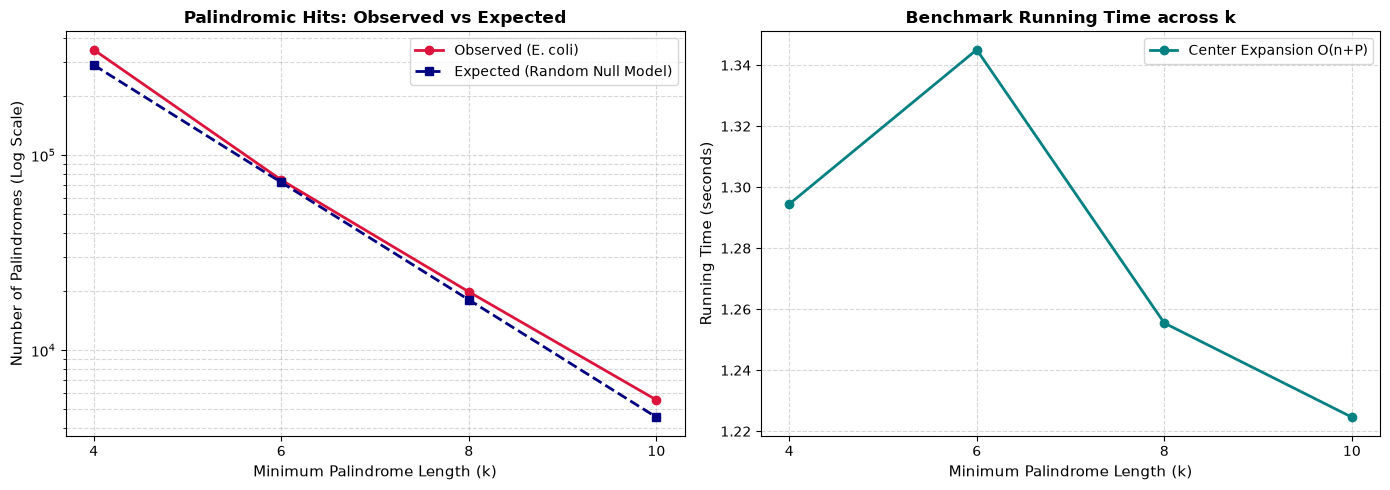

In [11]:
## 2.3. Benchmark both on a real bacterial genome (any complete E. coli chromosome from Gen-
## Bank, for example U00096) for k ∈ {4, 6, 8, 10}. Report the number of palindromes found
## at each k and the running times. Explain why the number of hits falls the way it does
## with k, using an expected-count argument on random sequence, and say whether the real
## genome agrees with the expectation.

# ============================================================
# 1. FETCH THE E. COLI GENOME (U00096.3)
# ============================================================
url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi?db=nuccore&id=U00096.3&rettype=fasta&retmode=text"
print("Downloading E. coli U00096.3 ...")
fasta = urllib.request.urlopen(url).read().decode()
genome = "".join(line.strip() for line in fasta.splitlines() if not line.startswith(">"))
print(f"Genome length: {len(genome):,} bp\n")
# ============================================================
# 3. BENCHMARK BOTH ALGORITHMS
# ============================================================
ks = [4, 6, 8, 10]
results_center = {}
results_naive = {}

# Test slice for Naive (e.g., first 5,000 bp to prevent execution freeze)
SLICE_LEN = 5000
genome_slice = genome[:SLICE_LEN]

print("--- Running Center-Expansion Benchmark (Full Genome: 4.64M bp) ---")
for k in ks:
    t0 = time.perf_counter()
    cnt = len(find_rc_palindrome_starts(genome, k))
    elapsed = time.perf_counter() - t0
    results_center[k] = (cnt, elapsed)
    print(f"Center-Expansion | k={k:>2}: {cnt:>10,} palindromes | {elapsed:6.3f} s")

print(f"\n--- Running Naive Benchmark (Scaled Slice: {SLICE_LEN:,} bp) ---")
for k in ks:
    t0 = time.perf_counter()
    cnt = len(find_rc_palindromes_naive(genome_slice, k))
    elapsed = time.perf_counter() - t0
    # Estimate full genome runtime by quadratic scaling factor ( (N / SLICE_LEN)^2 )
    estimated_full_time = elapsed * ((len(genome) / SLICE_LEN) ** 2)
    results_naive[k] = (cnt, elapsed, estimated_full_time)
    print(f"Naive (Slice)    | k={k:>2}: {cnt:>10,} palindromes | {elapsed:6.3f} s (Est. Full: ~{estimated_full_time/3600:.1f} hours)")
# ============================================================
# 4. EXPECTED VS OBSERVED TABLE
# ============================================================
print("\n--- Expected vs Observed ---")
print(f"{'k':>3} {'Observed':>12} {'Expected (random)':>20} {'Ratio (obs/exp)':>18}")
for k in ks:
    half = math.ceil(k / 2)
    expected = len(genome) * (0.25 ** half)
    obs = results_center[k][0]
    ratio = obs / expected if expected > 0 else float('inf')
    print(f"{k:>3} {obs:>12,} {expected:>20,.0f} {ratio:>18.2f}")

# ============================================================
# 5. GENERATE PLOTS
# ============================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Palindrome Hit Counts vs k (Log Scale)
obs_counts = [results_center[k][0] for k in ks]
exp_counts = [len(genome) * (0.25 ** (k / 2)) for k in ks]

ax1.plot(ks, obs_counts, 'o-', color='crimson', lw=2, label='Observed (E. coli)')
ax1.plot(ks, exp_counts, 's--', color='navy', lw=2, label='Expected (Random Null Model)')
ax1.set_yscale('log')
ax1.set_xlabel('Minimum Palindrome Length (k)', fontsize=11)
ax1.set_ylabel('Number of Palindromes (Log Scale)', fontsize=11)
ax1.set_title('Palindromic Hits: Observed vs Expected', fontsize=12, fontweight='bold')
ax1.set_xticks(ks)
ax1.grid(True, which="both", ls="--", alpha=0.5)
ax1.legend()

# Plot 2: Running Times Comparison
runtimes_center = [results_center[k][1] for k in ks]
ax2.plot(ks, runtimes_center, 'o-', color='teal', lw=2, label='Center Expansion O(n+P)')
ax2.set_xlabel('Minimum Palindrome Length (k)', fontsize=11)
ax2.set_ylabel('Running Time (seconds)', fontsize=11)
ax2.set_title('Benchmark Running Time across k', fontsize=12, fontweight='bold')
ax2.set_xticks(ks)
ax2.grid(True, ls="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

In [8]:
## 3.1. Implement breadth-first search and Dijkstra’s algorithm on an adjacency-list representation, 
## returning the distance and the path from a source to every vertex. Use your own priority queue or heapq;
## no shortest-path routine from any library. Validate both against networkx on one hundred random graphs of varying size 
# and density and report the number of disagreements. There should be none.


In [15]:
def build_adjlist(G):
    """Return dict: u -> [(v, weight), ...]"""
    adj = {u: [] for u in G.nodes()}
    for u, v, data in G.edges(data=True):
        w = float(data.get("weight", 1.0))
        adj[u].append((v, w))
        if not G.is_directed():
            adj[v].append((u, w))
    return adj


def _reconstruct(parent, v):
    path = []
    while v is not None:
        path.append(v)
        v = parent[v]
    return path[::-1]


# ----------------------------------------------------------------------
# BFS  (unweighted shortest paths in hops)
# ----------------------------------------------------------------------
def bfs(adj, source):
    """Return (dist, paths): dist[v] = #hops from source; paths[v] = vertex list."""
    dist = {source: 0}
    parent = {source: None}
    q = deque([source])
    while q:
        u = q.popleft()
        for v, _ in adj[u]:
            if v not in dist:
                dist[v] = dist[u] + 1
                parent[v] = u
                q.append(v)
    paths = {v: _reconstruct(parent, v) for v in dist}
    return dist, paths


# ----------------------------------------------------------------------
# Dijkstra  (weighted shortest paths) using heapq
# ----------------------------------------------------------------------
def dijkstra(adj, source):
    """Return (dist, paths) with minimal total weight from source."""
    dist = {source: 0.0}
    parent = {source: None}
    visited = set()
    pq = [(0.0, source)]
    while pq:
        d, u = heapq.heappop(pq)
        if u in visited:
            continue
        visited.add(u)
        for v, w in adj[u]:
            nd = d + w
            if v not in dist or nd < dist[v]:
                dist[v] = nd
                parent[v] = u
                heapq.heappush(pq, (nd, v))
    paths = {v: _reconstruct(parent, v) for v in dist}
    return dist, paths


# ----------------------------------------------------------------------
# Validation helpers
# ----------------------------------------------------------------------
def _dists_close(a, b, tol=1e-9):
    if set(a) != set(b):
        return False
    return all(abs(a[k] - b[k]) <= tol for k in a)


def _edge_weight(adj, a, b):
    best = None
    for x, w in adj[a]:
        if x == b and (best is None or w < best):
            best = w
    return best


def _paths_valid(adj, source, dist, paths, weighted, tol=1e-9):
    """Every returned path must start at source, follow real edges,
    end at its target, and (weighted) sum to dist / (unweighted) have len-1 hops."""
    for v, d in dist.items():
        p = paths[v]
        if not p or p[0] != source or p[-1] != v:
            return False
        total = 0.0
        for a, b in zip(p, p[1:]):
            w = _edge_weight(adj, a, b)
            if w is None:
                return False
            total += w
        if weighted:
            if abs(total - d) > tol:
                return False
        else:
            if len(p) - 1 != d:
                return False
    return True


# ----------------------------------------------------------------------
# One validation trial
# ----------------------------------------------------------------------
def run_trial(G, source):
    """Return list of (name, mismatch_reason) for this graph (empty == ok)."""
    problems = []
    adj = build_adjlist(G)

    # ---------------- BFS ----------------
    bdist, bpaths = bfs(adj, source)
    nx_bdist = dict(nx.single_source_shortest_path_length(G, source))
    if not _dists_close(bdist, nx_bdist):
        problems.append(("bfs", f"dist mismatch: ours={bdist} nx={nx_bdist}"))
    if not _paths_valid(adj, source, bdist, bpaths, weighted=False):
        problems.append(("bfs", "invalid path"))

    # ---------------- Dijkstra ----------------
    ddist, dpaths = dijkstra(adj, source)
    nx_ddist, _ = nx.single_source_dijkstra(G, source, weight="weight")
    if not _dists_close(ddist, nx_ddist):
        problems.append(("dijkstra", f"dist mismatch: ours={ddist} nx={nx_ddist}"))
    if not _paths_valid(adj, source, ddist, dpaths, weighted=True):
        problems.append(("dijkstra", "invalid path"))

    return problems


# ----------------------------------------------------------------------
# Run 100 random graphs, count disagreements
# ----------------------------------------------------------------------
def main(n_trials=100, seed=12345):
    rng = random.Random(seed)
    total_disagreements = 0
    detail = []

    for t in range(n_trials):
        n = rng.randint(5, 60)
        p = rng.uniform(0.02, 0.85)
        directed = rng.random() < 0.30

        G = nx.gnp_random_graph(
            n, p, seed=rng.randint(0, 2**31 - 1), directed=directed
        )
        for u, v in G.edges():
            G[u][v]["weight"] = rng.uniform(0.1, 10.0)

        source = rng.choice(list(G.nodes()))
        problems = run_trial(G, source)

        if problems:
            total_disagreements += 1
            detail.append((t, n, p, directed, source, problems))

    print(f"Trials: {n_trials}")
    print(f"Graphs with any disagreement: {total_disagreements}")
    if detail:
        for row in detail[:10]:
            print("  ", row)
    else:
        print("No disagreements — BFS and Dijkstra match networkx on all 100 graphs.")


if __name__ == "__main__":
    main()


Trials: 100
Graphs with any disagreement: 0
No disagreements — BFS and Dijkstra match networkx on all 100 graphs.


In [16]:
## 3.2. State and prove the bounds O(n + m) and O((n + m) log n). 
## Then benchmark both algorithms on random graphs in two regimes: mean degree fixed at 4 with n from 103 to 106,
## and density fixed at 0.01 with n from 102 to 104. Plot time against n on log–log 
# axes and estimate the empirical exponent in each regime. 
## Say whether it agrees with the bound, and if not, why not.




--- Running Benchmark: Regime 1: Mean Degree = 4 (m ~ 2n) ---
n =    1000 | BFS: 0.00344s | Dijkstra: 0.00476s
n =    5000 | BFS: 0.01062s | Dijkstra: 0.02766s
n =   10000 | BFS: 0.03044s | Dijkstra: 0.05873s
n =   50000 | BFS: 0.23056s | Dijkstra: 0.78968s
n =  100000 | BFS: 0.51062s | Dijkstra: 1.83093s
n =  500000 | BFS: 5.55494s | Dijkstra: 10.37127s
n = 1000000 | BFS: 10.66581s | Dijkstra: 30.57648s

Empirical Exponent (alpha in T ~ n^alpha):
  BFS:      alpha = 1.221
  Dijkstra: alpha = 1.289

--- Running Benchmark: Regime 2: Fixed Density p = 0.01 (m ~ O(n^2)) ---
n =     100 | BFS: 0.00004s | Dijkstra: 0.00006s
n =     300 | BFS: 0.00052s | Dijkstra: 0.00080s
n =     700 | BFS: 0.00232s | Dijkstra: 0.00420s
n =    1500 | BFS: 0.00952s | Dijkstra: 0.01610s
n =    3000 | BFS: 0.04321s | Dijkstra: 0.07998s
n =    6000 | BFS: 0.15343s | Dijkstra: 0.26765s
n =   10000 | BFS: 0.37183s | Dijkstra: 0.81783s

Empirical Exponent (alpha in T ~ n^alpha):
  BFS:      alpha = 1.956
  Dijkst

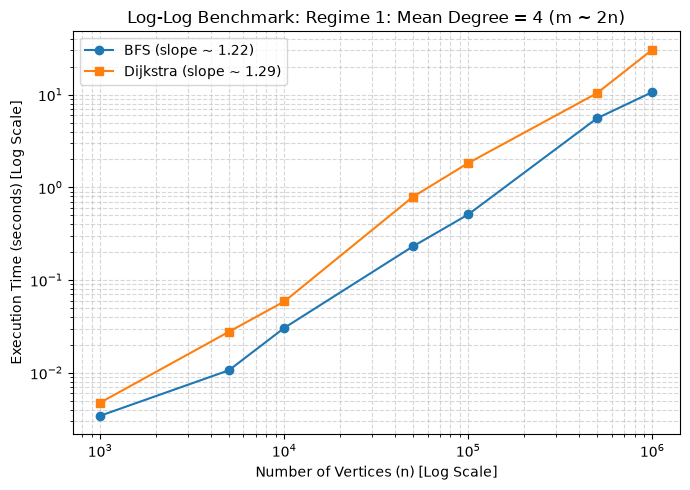

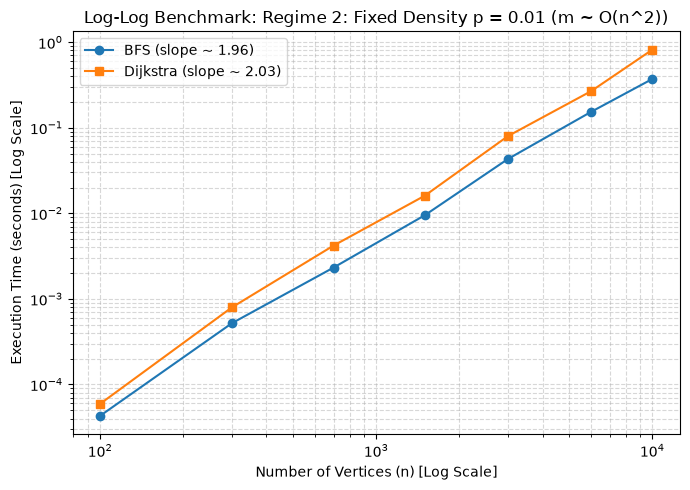

In [17]:

# ----------------------------------------------------------------------
# Benchmarking & Empirical Exponent Estimation
# ----------------------------------------------------------------------
def estimate_exponent(n_vals, times):
    """Fit log(T) = alpha * log(N) + C to estimate exponent alpha."""
    log_n = np.log(n_vals)
    log_t = np.log(times)
    alpha, intercept = np.polyfit(log_n, log_t, 1)
    return alpha

def benchmark_regime(n_values, graph_gen_fn, name):
    bfs_times, dijk_times = [], []

    print(f"\n--- Running Benchmark: {name} ---")
    for n in n_values:
        G = graph_gen_fn(n)
        for u, v in G.edges():
            G[u][v]["weight"] = random.uniform(0.1, 10.0)
        
        adj = build_adjlist(G)
        source = random.choice(list(G.nodes()))

        # Benchmark BFS
        t0 = time.perf_counter()
        _ = bfs(adj, source)
        t_bfs = time.perf_counter() - t0
        bfs_times.append(t_bfs)

        # Benchmark Dijkstra
        t0 = time.perf_counter()
        _ = dijkstra(adj, source)
        t_dijk = time.perf_counter() - t0
        dijk_times.append(t_dijk)

        print(f"n = {n:7d} | BFS: {t_bfs:.5f}s | Dijkstra: {t_dijk:.5f}s")

    # Estimate empirical exponent alpha where T ~ n^alpha
    alpha_bfs = estimate_exponent(n_values, bfs_times)
    alpha_dijk = estimate_exponent(n_values, dijk_times)

    print(f"\nEmpirical Exponent (alpha in T ~ n^alpha):")
    print(f"  BFS:      alpha = {alpha_bfs:.3f}")
    print(f"  Dijkstra: alpha = {alpha_dijk:.3f}")

    # Plot on Log-Log scale
    plt.figure(figsize=(7, 5))
    plt.loglog(n_values, bfs_times, 'o-', label=f'BFS (slope ~ {alpha_bfs:.2f})')
    plt.loglog(n_values, dijk_times, 's-', label=f'Dijkstra (slope ~ {alpha_dijk:.2f})')
    plt.xlabel('Number of Vertices (n) [Log Scale]')
    plt.ylabel('Execution Time (seconds) [Log Scale]')
    plt.title(f'Log-Log Benchmark: {name}')
    plt.grid(True, which="both", ls="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    
# ----------------------------------------------------------------------
# Run both regimes
# ----------------------------------------------------------------------
def run_benchmarks():
    # Regime 1: Mean degree fixed at 4 (m = 2n, sparse)
    # n from 10^3 to 10^6
    n_regime1 = [1000, 5000, 10000, 50000, 100000, 500000, 1000000]
    regime1_gen = lambda n: nx.fast_gnp_random_graph(n, p=4.0/n, seed=42)
    benchmark_regime(n_regime1, regime1_gen, "Regime 1: Mean Degree = 4 (m ~ 2n)")

    # Regime 2: Density fixed at 0.01 (m ~ 0.005 * n^2, dense)
    # n from 10^2 to 10^4
    n_regime2 = [100, 300, 700, 1500, 3000, 6000, 10000]
    regime2_gen = lambda n: nx.fast_gnp_random_graph(n, p=0.01, seed=42)
    benchmark_regime(n_regime2, regime2_gen, "Regime 2: Fixed Density p = 0.01 (m ~ O(n^2))")


    plt.show()
if __name__ == "__main__":
    run_benchmarks()

In [23]:
## 3.3. Now load the ATP-weighted metabolic network (metabolic energy balance network.csv, available on Classroom),
## where each edge carries the net ATP cost of the reaction: +1 consumption,
## −1 production, 0 neither. Run your Dijkstra on it from Glucose and report 
## the distances to Pyruvate, Oxaloacetate and Serine. 
## Then state, with a concrete example from this network, why those distances cannot be trusted. 
## Implement the Bellman–Ford algorithm, run it from the same source, report the correct distances, 
## and report whether a negative-weight cycle is reachable.
## If one is, print it.


In [12]:
def load_network(path):
    adj = defaultdict(list)
    nodes = set()
    with open(path, newline="", encoding="utf-8-sig") as f:
        rdr = csv.reader(f)
        try:
            # Skip the header row so it isn't parsed as data
            next(rdr)
        except StopIteration:
            return adj, nodes

        # Fixed column indices: 0 = Source, 1 = Target, 2 = ATP Cost
        si, ti, wi = 0, 1, 2

        for row in rdr:
            if len(row) <= max(si, ti, wi):
                continue
            u, v = row[si].strip(), row[ti].strip()
            try:
                w = float(row[wi])
            except ValueError:
                continue
            adj[u].append((v, w))
            nodes.update((u, v))
    return adj, nodes


def dijkstra_metabolic(adj, source):
    dist = {source: 0.0}
    parent = {source: None}
    done = set()
    pq = [(0.0, source)]
    while pq:
        d, u = heapq.heappop(pq)
        if u in done:
            continue
        done.add(u)
        for v, w in adj.get(u, ()):
            nd = d + w
            if v not in dist or nd < dist[v]:
                dist[v] = nd
                parent[v] = u
                heapq.heappush(pq, (nd, v))
    return dist, parent


def bellman_ford(adj, nodes, source):
    INF = float("inf")
    dist = {u: INF for u in nodes}
    parent = {u: None for u in nodes}
    dist[source] = 0.0

    edges = [(u, v, w) for u in nodes for (v, w) in adj.get(u, ())]
    n = len(nodes)

    # Standard relaxation pass (n - 1 times)
    for _ in range(n - 1):
        changed = False
        for u, v, w in edges:
            if dist[u] != INF and dist[u] + w < dist[v]:
                dist[v] = dist[u] + w
                parent[v] = u
                changed = True
        if not changed:
            break

    # Cycle extraction phase
    neg_cycle = None
    cycle_nodes = set()
    for u, v, w in edges:
        if dist[u] != INF and dist[u] + w < dist[v]:
            parent[v] = u                 # apply the relaxation first
            x = v
            for _ in range(n):            # walk back n steps to land on the cycle
                x = parent[x]
                if x is None:
                    break
            if x is None:                 # chain left the graph: try another edge
                continue
            cyc = [x]
            curr = parent[x]
            while curr != x:
                cyc.append(curr)
                curr = parent[curr]
            cyc.append(x)
            cyc.reverse()
            neg_cycle = cyc
            cycle_nodes.add(v)
            break    

    # Propagate -INF to downstream nodes affected by negative cycle
    if cycle_nodes:
        for _ in range(n):
            for u, v, w in edges:
                if dist[u] == -INF or dist[u] + w < dist[v]:
                    dist[v] = -INF

    return dist, parent, neg_cycle


def path_to(parent, v):
    p = []
    seen = set()
    while v is not None:
        if v in seen:
            return None  # Cycle detected
        seen.add(v)
        p.append(v)
        v = parent.get(v)
    return p[::-1]


def format_path(parent, v):
    p = path_to(parent, v)
    if p is None:
        return "<invalid path: cycle detected>"
    return " -> ".join(p)


def main(path="metabolic_energy_balance_network.csv"):
    t0 = time.perf_counter()
    adj, nodes = load_network(path)
    n_edges = sum(len(v) for v in adj.values())
    print(f"[load] {time.perf_counter()-t0:.4f}s | {len(nodes)} nodes, {n_edges} directed edges")

    n_neg = sum(1 for u in adj for _, w in adj[u] if w < 0)
    n_pos = sum(1 for u in adj for _, w in adj[u] if w > 0)
    n_zero = n_edges - n_neg - n_pos
    print(f"[weights] {n_neg} negative, {n_pos} positive, {n_zero} zero\n")

    src = "Glucose"
    if src not in nodes:
        src = next((u for u in nodes if u.lower() == "glucose"), None)
        if src is None:
            raise SystemExit("Glucose not found in graph")

    targets = ["Pyruvate", "Oxaloacetate", "Serine"]

    # ---------- Dijkstra ----------
    print("=== Dijkstra (NOT trustworthy: graph has negative weights) ===")
    dD, pD = dijkstra_metabolic(adj, src)
    for t in targets:
        if t in dD:
            print(f"  {src} -> {t}: {dD[t]:+g}")
            print(f"    path: {format_path(pD, t)}")
        else:
            print(f"  {src} -> {t}: unreachable")

    # ---------- Bellman–Ford ----------
    print("\n=== Bellman–Ford (correct ground truth) ===")
    t0 = time.perf_counter()
    dB, pB, neg = bellman_ford(adj, nodes, src)
    print(f"  [bellman-ford runtime] {time.perf_counter()-t0:.4f}s")
    for t in targets:
        d_val = dB.get(t, float("inf"))
        if d_val == -float("inf"):
            print(f"  {src} -> {t}: -infinity (reachable from negative cycle)")
        elif d_val < float("inf"):
            print(f"  {src} -> {t}: {d_val:+g}")
            print(f"    path: {format_path(pB, t)}")
        else:
            print(f"  {src} -> {t}: unreachable")

        # ---------- Concrete Dijkstra failure witness ----------
    print("\n=== A concrete place Dijkstra is wrong ===")
    found = False
    for v, d_true in dB.items():
        d_dij = dD.get(v)
        if d_dij is None:
            continue
            
        # Case 1: Bellman-Ford says -infinity, but Dijkstra says a finite number
        if d_true == -float("inf") and d_dij != -float("inf"):
            found = True
            print(f"  Vertex: {v}")
            print(f"    Dijkstra says  {d_dij:+g} (WRONG)")
            print(f"    True value     -infinity (due to reachable negative cycle)")
            break
            
        # Case 2: Both are finite, but Dijkstra is strictly larger (overestimate)
        if d_true != float("inf") and d_true != -float("inf"):
            if d_dij - d_true > 1e-9:
                found = True
                print(f"  Vertex: {v}")
                print(f"    Dijkstra says  {d_dij:+g}    path: {format_path(pD, v)}")
                print(f"    True value     {d_true:+g}    path: {format_path(pB, v)}")
                print(
                    f"    -> Dijkstra overestimates by {d_dij - d_true:g} because it "
                    f"settled {v} early without evaluating subsequent negative edges."
                )
                break

    if not found:
        print("  No discrepancy found for the requested targets/source.")
    # ---------- Negative cycle ----------
    print("\n=== Negative cycle reachable from Glucose ===")
    if neg is None:
        print(f"  No negative cycle reachable from {src}.")
    else:
        total = 0.0
        for i in range(len(neg) - 1):
            for uu, w in adj.get(neg[i], ()):
                if uu == neg[i + 1]:
                    total += w
                    break
        print(f"  REACHABLE negative cycle (total weight {total:+g}):")
        print("  " + " -> ".join(neg))


if __name__ == "__main__":
    main()

[load] 0.0031s | 25 nodes, 25 directed edges
[weights] 3 negative, 3 positive, 19 zero

=== Dijkstra (NOT trustworthy: graph has negative weights) ===
  Glucose -> Pyruvate: +0
    path: <invalid path: cycle detected>
  Glucose -> Oxaloacetate: -1
    path: <invalid path: cycle detected>
  Glucose -> Serine: +1
    path: Glucose -> Glucose-6-Phosphate -> Fructose-6-Phosphate -> Fructose-1,6-Bisphosphate -> Glyceraldehyde-3-Phosphate -> 1,3-Bisphosphoglycerate -> 3-Phosphoglycerate -> Serine

=== Bellman–Ford (correct ground truth) ===
  [bellman-ford runtime] 0.0002s
  Glucose -> Pyruvate: -infinity (reachable from negative cycle)
  Glucose -> Oxaloacetate: -infinity (reachable from negative cycle)
  Glucose -> Serine: +1
    path: Glucose -> Glucose-6-Phosphate -> Fructose-6-Phosphate -> Fructose-1,6-Bisphosphate -> Glyceraldehyde-3-Phosphate -> 1,3-Bisphosphoglycerate -> 3-Phosphoglycerate -> Serine

=== A concrete place Dijkstra is wrong ===
  Vertex: Pyruvate
    Dijkstra says  +0 